In [ ]:
# ==========================================================
# PENGAMBILAN DATA
# ==========================================================

import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# GANTI SESUAI NAMA FILE DAN KOLOM DATASET KAMU
file_path = "/content/mobile_jkn_reviews (2).csv"
text_column = "review_text"
rating_column = "rating"

# Load dataset
df = pd.read_csv(file_path)

print("Jumlah data awal:", len(df))
print("Kolom dataset:")
print(df.columns)

df.head()

Jumlah data awal: 30000
Kolom dataset:
Index(['review_id', 'user_name', 'rating', 'review_text', 'review_title',
       'review_date', 'thumbs_up_count', 'app_version', 'review_length',
       'word_count', 'sentiment_label', 'sentiment_positive',
       'sentiment_neutral', 'sentiment_negative'],
      dtype='object')


,review_id,user_name,rating,review_text,review_title,review_date,thumbs_up_count,app_version,review_length,word_count,sentiment_label,sentiment_positive,sentiment_neutral,sentiment_negative
0,1d3db3c1-dda5-44c4-a853-b231614c7ecf,Sri daryati Sri daryati,5,bagus sekali,4/8/2026 11:10,4/8/2026 11:10,0,Unknown,12,2,positive,1,0,0
1,85068746-0453-4d48-8031-021aeac58108,Rustam Azis,5,kenapa setelah update ke versi terbaru sering ...,4/8/2026 10:55,4/8/2026 10:55,0,4.16.1,150,21,positive,1,0,0
2,d5d9fbc1-3776-445e-988e-c23a8284f6aa,Santi Naureen,5,puas,4/8/2026 10:51,4/8/2026 10:51,0,4.16.1,4,1,positive,1,0,0
3,3d549de2-a2d4-45da-a8bb-1168d06e4635,KIA 313,1,cuma untuk dapetin kode otp saja susah nya min...,4/8/2026 10:50,4/8/2026 10:50,0,4.16.1,139,23,negative,0,0,1
4,5049f35e-20d3-4a2b-a7ad-5f35e0945d6b,cijo yanto,1,sms gak pernah masuk jaringan bagus tapi gak a...,4/8/2026 10:48,4/8/2026 10:48,0,4.16.1,248,45,negative,0,0,1


In [ ]:
# ==========================================================
# CEK DATA KOSONG DAN DUPLIKAT
# ==========================================================

print("Jumlah data kosong per kolom:")
print(df.isnull().sum())

print("\nJumlah duplikat berdasarkan ulasan:", df.duplicated(subset=[text_column]).sum())

Jumlah data kosong per kolom:
review_id             0
user_name             0
rating                0
review_text           0
review_title          0
review_date           0
thumbs_up_count       0
app_version           0
review_length         0
word_count            0
sentiment_label       0
sentiment_positive    0
sentiment_neutral     0
sentiment_negative    0
case_folding          0
cleansing             0
tokenizing            0
stopword_removal      0
normalization         0
sentimen_rating       0
stemming              0
final_text            0
skor_lexicon          0
sentimen_lexicon      0
dtype: int64

Jumlah duplikat berdasarkan ulasan: 0


In [ ]:
# ==========================================================
# HAPUS DATA KOSONG DAN DUPLIKAT
# ==========================================================

df = df.dropna(subset=[text_column])
df = df.drop_duplicates(subset=[text_column])
df = df.reset_index(drop=True)

print("Jumlah data setelah hapus kosong dan duplikat:", len(df))

df.head()

Jumlah data setelah hapus kosong dan duplikat: 20873


,review_id,user_name,rating,review_text,review_title,review_date,thumbs_up_count,app_version,review_length,word_count,sentiment_label,sentiment_positive,sentiment_neutral,sentiment_negative
0,1d3db3c1-dda5-44c4-a853-b231614c7ecf,Sri daryati Sri daryati,5,bagus sekali,4/8/2026 11:10,4/8/2026 11:10,0,Unknown,12,2,positive,1,0,0
1,85068746-0453-4d48-8031-021aeac58108,Rustam Azis,5,kenapa setelah update ke versi terbaru sering ...,4/8/2026 10:55,4/8/2026 10:55,0,4.16.1,150,21,positive,1,0,0
2,d5d9fbc1-3776-445e-988e-c23a8284f6aa,Santi Naureen,5,puas,4/8/2026 10:51,4/8/2026 10:51,0,4.16.1,4,1,positive,1,0,0
3,3d549de2-a2d4-45da-a8bb-1168d06e4635,KIA 313,1,cuma untuk dapetin kode otp saja susah nya min...,4/8/2026 10:50,4/8/2026 10:50,0,4.16.1,139,23,negative,0,0,1
4,5049f35e-20d3-4a2b-a7ad-5f35e0945d6b,cijo yanto,1,sms gak pernah masuk jaringan bagus tapi gak a...,4/8/2026 10:48,4/8/2026 10:48,0,4.16.1,248,45,negative,0,0,1


In [ ]:
# ==========================================================
# 4.2.1 CASE FOLDING
# ==========================================================

def case_folding(text):
    return str(text).lower()

df['case_folding'] = df[text_column].apply(case_folding)

df[[text_column, 'case_folding']].head()

,review_text,case_folding
0,bagus sekali,bagus sekali
1,kenapa setelah update ke versi terbaru sering ...,kenapa setelah update ke versi terbaru sering ...
2,puas,puas
3,cuma untuk dapetin kode otp saja susah nya min...,cuma untuk dapetin kode otp saja susah nya min...
4,sms gak pernah masuk jaringan bagus tapi gak a...,sms gak pernah masuk jaringan bagus tapi gak a...


In [ ]:
# ==========================================================
# 4.2.2 CLEANSING
# ==========================================================

def cleansing(text):
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)  # hapus URL
    text = re.sub(r'@\w+', '', text)                     # hapus mention
    text = re.sub(r'#\w+', '', text)                     # hapus hashtag
    text = re.sub(r'\d+', '', text)                      # hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation))  # hapus tanda baca
    text = re.sub(r'[^a-zA-Z\s]', '', text)              # hapus karakter selain huruf
    text = re.sub(r'\s+', ' ', text).strip()             # hapus spasi berlebih
    return text

df['cleansing'] = df['case_folding'].apply(cleansing)

df[[text_column, 'cleansing']].head()

,review_text,cleansing
0,bagus sekali,bagus sekali
1,kenapa setelah update ke versi terbaru sering ...,kenapa setelah update ke versi terbaru sering ...
2,puas,puas
3,cuma untuk dapetin kode otp saja susah nya min...,cuma untuk dapetin kode otp saja susah nya min...
4,sms gak pernah masuk jaringan bagus tapi gak a...,sms gak pernah masuk jaringan bagus tapi gak a...


In [ ]:
# ==========================================================
# 4.2.3 TOKENIZING
# ==========================================================

!pip install nltk -q

import nltk
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')

def tokenizing(text):
    return word_tokenize(text)

df['tokenizing'] = df['cleansing'].apply(tokenizing)

df[['cleansing', 'tokenizing']].head()

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,cleansing,tokenizing
0,bagus sekali,"[bagus, sekali]"
1,kenapa setelah update ke versi terbaru sering ...,"[kenapa, setelah, update, ke, versi, terbaru, ..."
2,puas,[puas]
3,cuma untuk dapetin kode otp saja susah nya min...,"[cuma, untuk, dapetin, kode, otp, saja, susah,..."
4,sms gak pernah masuk jaringan bagus tapi gak a...,"[sms, gak, pernah, masuk, jaringan, bagus, tap..."


In [ ]:
# ==========================================================
# 4.2.4 STOPWORD REMOVAL
# ==========================================================

from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('indonesian'))

# Tambahan stopword khusus ulasan aplikasi
custom_stopwords = {
    'yg', 'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu',
    'saya', 'aku', 'kami', 'kita', 'nya', 'aja', 'sih',
    'dong', 'deh', 'nih', 'lah', 'pun', 'juga', 'untuk',
    'dengan', 'karena', 'kalau', 'kalo', 'jadi', 'sudah',
    'udah', 'akan', 'agar', 'aplikasi', 'app', 'apps'
}

stop_words.update(custom_stopwords)

def stopword_removal(tokens):
    return [word for word in tokens if word not in stop_words]

df['stopword_removal'] = df['tokenizing'].apply(stopword_removal)

df[['tokenizing', 'stopword_removal']].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,tokenizing,stopword_removal
0,"[bagus, sekali]",[bagus]
1,"[kenapa, setelah, update, ke, versi, terbaru, ...","[update, versi, terbaru, log, out, sendirijadi..."
2,[puas],[puas]
3,"[cuma, untuk, dapetin, kode, otp, saja, susah,...","[dapetin, kode, otp, susah, ampun, sehari, sem..."
4,"[sms, gak, pernah, masuk, jaringan, bagus, tap...","[sms, gak, masuk, jaringan, bagus, gak, gilira..."


In [ ]:
# ==========================================================
# 4.2.5 NORMALIZATION
# ==========================================================

normalization_dict = {
    'gk': 'tidak',
    'ga': 'tidak',
    'gak': 'tidak',
    'nggak': 'tidak',
    'ngga': 'tidak',
    'tdk': 'tidak',
    'tak': 'tidak',
    'bgt': 'banget',
    'bangettt': 'banget',
    'apk': 'aplikasi',
    'apps': 'aplikasi',
    'app': 'aplikasi',
    'aplikasinya': 'aplikasi',
    'lemot': 'lambat',
    'lelet': 'lambat',
    'eror': 'error',
    'err': 'error',
    'gabisa': 'tidak bisa',
    'gbs': 'tidak bisa',
    'ga bisa': 'tidak bisa',
    'gak bisa': 'tidak bisa',
    'tdk bisa': 'tidak bisa',
    'loginya': 'login',
    'loginnya': 'login',
    'masuknya': 'masuk',
    'daftarnya': 'daftar',
    'verifikasinya': 'verifikasi',
    'otpnya': 'otp',
    'updatean': 'pembaruan',
    'diupdate': 'diperbarui',
    'diperbaharui': 'diperbarui',
    'mantab': 'mantap',
    'mantul': 'mantap',
    'ok': 'oke',
    'jos': 'bagus',
    'recommended': 'rekomendasi',
    'ribet': 'rumit',
    'susah': 'sulit',
    'payah': 'buruk',
    'parahh': 'parah',
    'baguss': 'bagus',
    'mantapp': 'mantap'
}

def normalization(tokens):
    normalized_words = []

    for word in tokens:
        if word in normalization_dict:
            normalized_words.extend(normalization_dict[word].split())
        else:
            normalized_words.append(word)

    return normalized_words

df['normalization'] = df['stopword_removal'].apply(normalization)

df[['stopword_removal', 'normalization']].head()

,stopword_removal,normalization
0,[bagus],[bagus]
1,"[update, versi, terbaru, log, out, sendirijadi...","[update, versi, terbaru, log, out, sendirijadi..."
2,[puas],[puas]
3,"[dapetin, kode, otp, susah, ampun, sehari, sem...","[dapetin, kode, otp, sulit, ampun, sehari, sem..."
4,"[sms, gak, masuk, jaringan, bagus, gak, gilira...","[sms, tidak, masuk, jaringan, bagus, tidak, gi..."


In [ ]:
# ==========================================================
# 4.2.6 STEMMING
# ==========================================================

!pip install Sastrawi -q

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

factory = StemmerFactory()
stemmer = factory.create_stemmer()

def stemming(tokens):
    return [stemmer.stem(word) for word in tokens]

df['stemming'] = df['normalization'].apply(stemming)

df[['normalization', 'stemming']].head()

,normalization,stemming
0,[bagus],[bagus]
1,"[update, versi, terbaru, log, out, sendirijadi...","[update, versi, baru, log, out, sendirijadi, m..."
2,[puas],[puas]
3,"[dapetin, kode, otp, sulit, ampun, sehari, sem...","[dapetin, kode, otp, sulit, ampun, hari, malam..."
4,"[sms, tidak, masuk, jaringan, bagus, tidak, gi...","[sms, tidak, masuk, jaring, bagus, tidak, gili..."


In [ ]:
# ==========================================================
# 4.3.1 LABELLING BERDASARKAN RATING
# ==========================================================

def label_rating(score):
    if score <= 2:
        return 'Negatif'
    elif score == 3:
        return 'Netral'
    else:
        return 'Positif'

df['sentimen_rating'] = df[rating_column].apply(label_rating)

print("Distribusi sentimen berdasarkan rating:")
print(df['sentimen_rating'].value_counts())

df[[text_column, rating_column, 'sentimen_rating']].head()

Distribusi sentimen berdasarkan rating:
sentimen_rating
Positif    9994
Negatif    9733
Netral     1146
Name: count, dtype: int64


,review_text,rating,sentimen_rating
0,bagus sekali,5,Positif
1,kenapa setelah update ke versi terbaru sering ...,5,Positif
2,puas,5,Positif
3,cuma untuk dapetin kode otp saja susah nya min...,1,Negatif
4,sms gak pernah masuk jaringan bagus tapi gak a...,1,Negatif


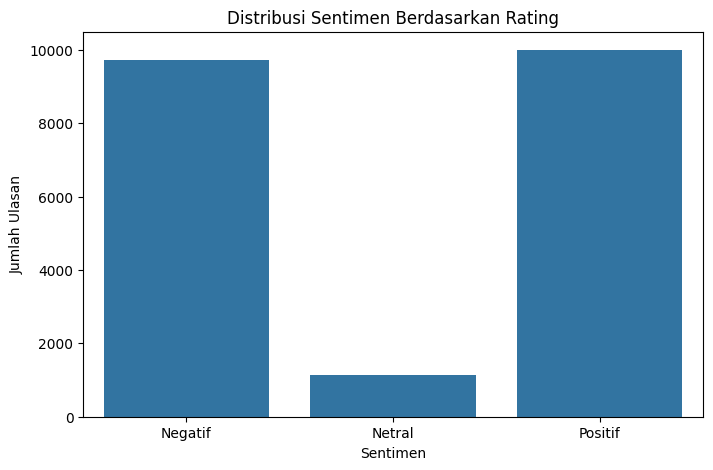

In [ ]:
# ==========================================================
# VISUALISASI LABEL BERDASARKAN RATING
# ==========================================================

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='sentimen_rating',
    order=['Negatif', 'Netral', 'Positif']
)
plt.title('Distribusi Sentimen Berdasarkan Rating')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.show()

In [ ]:
import pandas as pd
# ==========================================================
# 4.3.2 LABELLING BERDASARKAN KAMUS / LEXICON
# ==========================================================

# Defensive programming: Ensure 'stemming' column exists
if 'stemming' not in df.columns:
    print("Warning: 'stemming' column not found. Attempting to re-create it for robust execution.")
    try:
        # Re-import and re-define from 4.2.6 STEMMING (cell 6BqQklyfA33g)
        from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
        factory = StemmerFactory()
        stemmer = factory.create_stemmer()

        def _recreate_stemming_func(tokens):
            if isinstance(tokens, list):
                return [stemmer.stem(word) for word in tokens]
            return []  # Handle cases where 'normalization' might not be a list

        if 'normalization' in df.columns:
            df['stemming'] = df['normalization'].apply(_recreate_stemming_func)
            print("Successfully re-created 'stemming' column.")
        else:
            print("Error: 'normalization' column is also missing, cannot re-create 'stemming'. Please ensure all previous preprocessing steps are run.")
    except ImportError:
        print("Error: Sastrawi library not found. Please ensure it's installed (e.g., '!pip install Sastrawi').")
    except Exception as e:
        print(f"An unexpected error occurred while attempting to re-create 'stemming': {e}")


positive_words = {
    'bagus': 3,
    'baik': 3,
    'mantap': 3,
    'mudah': 3,
    'cepat': 3,
    'lancar': 3,
    'bantu': 2,
    'puas': 3,
    'praktis': 3,
    'nyaman': 3,
    'keren': 3,
    'suka': 2,
    'stabil': 3,
    'manfaat': 2,
    'solusi': 2,
    'jelas': 2,
    'lengkap': 2,
    'hasil': 2,
    'aman': 2,
    'valid': 2,
    'sukses': 3,
    'normal': 2,
    'oke': 2,
    'rekomendasi': 2,
    'responsif': 3,
    'efektif': 2,
    'efisien': 2,
    'simple': 2,
    'simpel': 2,
    'terbaik': 3,
    'memuaskan': 3,
    'terpercaya': 3
}

negative_words = {
    'buruk': -3,
    'jelek': -3,
    'parah': -3,
    'sulit': -3,
    'lambat': -3,
    'lemot': -3,
    'error': -3,
    'gagal': -3,
    'crash': -3,
    'bug': -3,
    'masalah': -2,
    'kendala': -2,
    'ribet': -3,
    'rumit': -3,
    'kecewa': -3,
    'hilang': -2,
    'kurang': -2,
    'bohong': -3,
    'payah': -3,
    'login': -1,
    'daftar': -1,
    'verifikasi': -1,
    'otp': -1,
    'server': -2,
    'down': -3,
    'ganggu': -2,
    'loading': -2,
    'macet': -2,
    'ulang': -1,
    'hapus': -1,
    'blank': -2,
    'kosong': -2,
    'lama': -2,
    'tolak': -2,
    'invalid': -2,
    'tidak': -1,
    'bisa': -1,
    'gajelas': -3,
    'sampah': -3,
    'mengecewakan': -3,
    'burik': -3
}

lexicon_dict = {}
lexicon_dict.update(positive_words)
lexicon_dict.update(negative_words)

def hitung_skor_lexicon(text):
    words = str(text).split()
    score = 0

    for word in words:
        if word in lexicon_dict:
            score += lexicon_dict[word]

    return score

def label_lexicon(score):
    if score > 4:
        return 'Positif'
    elif score < 3:
        return 'Negatif'
    else:
        return 'Netral'

df['final_text'] = df['stemming'].apply(lambda x: ' '.join(x))
df['skor_lexicon'] = df['final_text'].apply(hitung_skor_lexicon)
df['sentimen_lexicon'] = df['skor_lexicon'].apply(label_lexicon)

print("Distribusi sentimen berdasarkan kamus:")
print(df['sentimen_lexicon'].value_counts())

df[[text_column, 'final_text', 'skor_lexicon', 'sentimen_lexicon']].head()

Successfully re-created 'stemming' column.
Distribusi sentimen berdasarkan kamus:
sentimen_lexicon
Negatif    15820
Netral      3080
Positif     1973
Name: count, dtype: int64


,review_text,final_text,skor_lexicon,sentimen_lexicon
0,bagus sekali,bagus,3,Netral
1,kenapa setelah update ke versi terbaru sering ...,update versi baru log out sendirijadi masuk aw...,-2,Negatif
2,puas,puas,3,Netral
3,cuma untuk dapetin kode otp saja susah nya min...,dapetin kode otp sulit ampun hari malam sinyal...,-1,Negatif
4,sms gak pernah masuk jaringan bagus tapi gak a...,sms tidak masuk jaring bagus tidak gilir email...,-9,Negatif


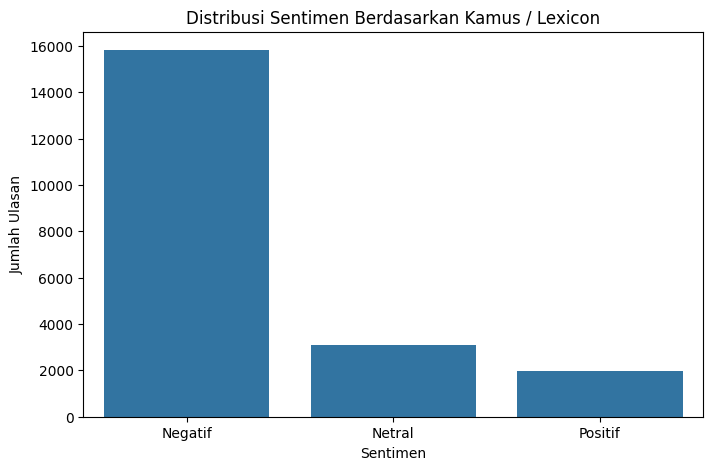

In [ ]:
# ==========================================================
# VISUALISASI LABEL BERDASARKAN KAMUS
# ==========================================================

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='sentimen_lexicon',
    order=['Negatif', 'Netral', 'Positif']
)
plt.title('Distribusi Sentimen Berdasarkan Kamus / Lexicon')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Ulasan')
plt.show()

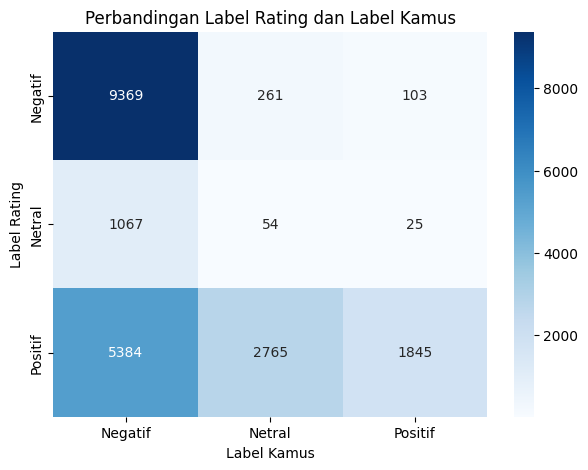

Label Kamus,Negatif,Netral,Positif
Label Rating,,,
Negatif,9369,261,103
Netral,1067,54,25
Positif,5384,2765,1845


In [ ]:
# ==========================================================
# PERBANDINGAN LABEL RATING DAN KAMUS
# ==========================================================

comparison_label = pd.crosstab(
    df['sentimen_rating'],
    df['sentimen_lexicon'],
    rownames=['Label Rating'],
    colnames=['Label Kamus']
)

plt.figure(figsize=(7, 5))
sns.heatmap(comparison_label, annot=True, fmt='d', cmap='Blues')
plt.title('Perbandingan Label Rating dan Label Kamus')
plt.xlabel('Label Kamus')
plt.ylabel('Label Rating')
plt.show()

comparison_label

In [ ]:
# ==========================================================
# 4.4 VISUALISASI WORDCLOUD SENTIMEN
# ==========================================================

!pip install wordcloud -q

from wordcloud import WordCloud

In [ ]:
# ==========================================================
# 4.4 VISUALISASI WORDCLOUD SENTIMEN
# ==========================================================

!pip install wordcloud -q

from wordcloud import WordCloud

### Wordcloud Keseluruhan (Overall Wordcloud)

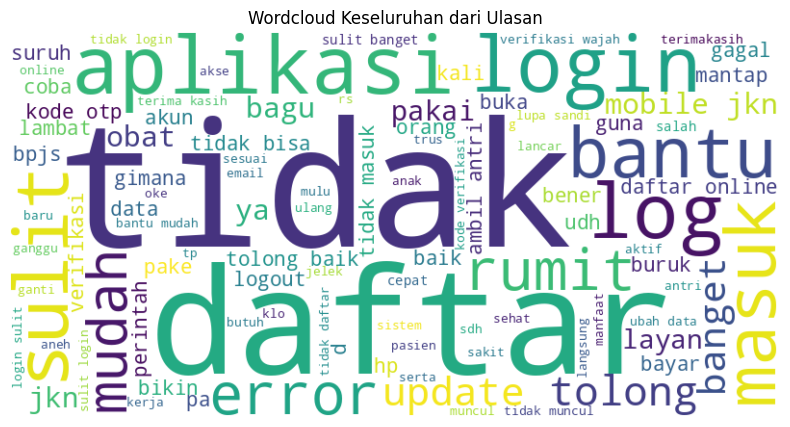

In [ ]:
# ==========================================================
# WORDCLOUD KESELURUHAN
# ==========================================================

all_text = ' '.join(df['final_text'])

wordcloud_overall = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100
).generate(all_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_overall, interpolation='bilinear')
plt.axis('off')
plt.title('Wordcloud Keseluruhan dari Ulasan')
plt.show()

In [ ]:
# ==========================================================
# 4.4.1 WORDCLOUD POSITIF
# ==========================================================

positive_text = ' '.join(df[df['Sentimen'] == 'Positif']['final_text'])

wordcloud_positive = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.axis('off')
plt.title('Wordcloud Sentimen Positif')
plt.show()

KeyError: 'Sentimen'

In [ ]:
# ==========================================================
# 4.4.2 WORDCLOUD NEGATIF
# ==========================================================

negative_text = ' '.join(df[df['Sentimen'] == 'Negatif']['final_text'])

wordcloud_negative = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100
).generate(negative_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.axis('off')
plt.title('Wordcloud Sentimen Negatif')
plt.show()

In [ ]:
# ==========================================================
# 4.4.3 WORDCLOUD NETRAL
# ==========================================================

neutral_text = ' '.join(df[df['Sentimen'] == 'Netral']['final_text'])

wordcloud_neutral = WordCloud(
    width=800,
    height=400,
    background_color='white',
    max_words=100
).generate(neutral_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud_neutral, interpolation='bilinear')
plt.axis('off')
plt.title('Wordcloud Sentimen Netral')
plt.show()

In [ ]:
# ==========================================================
# VISUALISASI TOP 20 KATA PER SENTIMEN
# ==========================================================

from collections import Counter

def plot_top_words(sentiment, top_n=20):
    text_data = df[df['Sentimen'] == sentiment]['final_text']
    words = ' '.join(text_data).split()
    word_freq = Counter(words).most_common(top_n)

    word_df = pd.DataFrame(word_freq, columns=['Kata', 'Frekuensi'])

    plt.figure(figsize=(10, 6))
    sns.barplot(data=word_df, x='Frekuensi', y='Kata')
    plt.title(f'Top {top_n} Kata Sentimen {sentiment}')
    plt.xlabel('Frekuensi')
    plt.ylabel('Kata')
    plt.show()

plot_top_words('Positif')
plot_top_words('Negatif')
plot_top_words('Netral')

In [ ]:
# ==========================================================
# 4.5 SPLITTING DATA TRAINING DAN TESTING
# ==========================================================

from sklearn.model_selection import train_test_split

X = df['final_text']
y = df['Sentimen']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

print("\nDistribusi label data training:")
print(y_train.value_counts())

print("\nDistribusi label data testing:")
print(y_test.value_counts())

In [ ]:
# ==========================================================
# VISUALISASI DISTRIBUSI TRAINING DAN TESTING
# ==========================================================

train_dist = y_train.value_counts().reset_index()
train_dist.columns = ['Sentimen', 'Jumlah']
train_dist['Data'] = 'Training'

test_dist = y_test.value_counts().reset_index()
test_dist.columns = ['Sentimen', 'Jumlah']
test_dist['Data'] = 'Testing'

split_dist = pd.concat([train_dist, test_dist])

plt.figure(figsize=(8, 5))
sns.barplot(data=split_dist, x='Sentimen', y='Jumlah', hue='Data')
plt.title('Distribusi Sentimen pada Data Training dan Testing')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Data')
plt.show()

In [ ]:
# ==========================================================
# 4.6 TF-IDF
# ==========================================================

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Ukuran TF-IDF data training:", X_train_tfidf.shape)
print("Ukuran TF-IDF data testing:", X_test_tfidf.shape)

In [ ]:
# ==========================================================
# VISUALISASI TOP 20 FITUR TF-IDF
# ==========================================================

tfidf_sum = X_train_tfidf.sum(axis=0)
tfidf_scores = np.asarray(tfidf_sum).flatten()

tfidf_df = pd.DataFrame({
    'Kata': tfidf.get_feature_names_out(),
    'Skor_TFIDF': tfidf_scores
})

top_tfidf = tfidf_df.sort_values(by='Skor_TFIDF', ascending=False).head(20)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_tfidf, x='Skor_TFIDF', y='Kata')
plt.title('Top 20 Kata Berdasarkan Skor TF-IDF')
plt.xlabel('Skor TF-IDF')
plt.ylabel('Kata')
plt.show()

In [ ]:
# ==========================================================
# ENCODE LABEL SENTIMEN
# ==========================================================

from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Kelas sentimen:", label_encoder.classes_)
print("Contoh label encoded:", y_train_encoded[:10])

y_train_categorical = to_categorical(y_train_encoded)
y_test_categorical = to_categorical(y_test_encoded)

print("Shape y_train_categorical:", y_train_categorical.shape)
print("Shape y_test_categorical:", y_test_categorical.shape)

In [ ]:
# ==========================================================
# 4.7 PENERAPAN RANDOM OVERSAMPLING / ROS
# ==========================================================

!pip install imbalanced-learn -q

from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(X_train_tfidf, y_train_encoded)

print("Distribusi sebelum ROS:")
print(pd.Series(y_train_encoded).value_counts())

print("\nDistribusi setelah ROS:")
print(pd.Series(y_train_ros).value_counts())

In [ ]:
# ==========================================================
# VISUALISASI SEBELUM DAN SESUDAH ROS
# ==========================================================

before_ros = pd.Series(y_train_encoded).value_counts().sort_index()
after_ros = pd.Series(y_train_ros).value_counts().sort_index()

ros_df = pd.DataFrame({
    'Sentimen': label_encoder.classes_,
    'Sebelum ROS': before_ros.values,
    'Sesudah ROS': after_ros.values
})

ros_df_melt = ros_df.melt(
    id_vars='Sentimen',
    value_vars=['Sebelum ROS', 'Sesudah ROS'],
    var_name='Kondisi',
    value_name='Jumlah'
)

plt.figure(figsize=(8, 5))
sns.barplot(data=ros_df_melt, x='Sentimen', y='Jumlah', hue='Kondisi')
plt.title('Perbandingan Distribusi Sentimen Sebelum dan Sesudah ROS')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah Data')
plt.show()

ros_df

In [ ]:
# ==========================================================
# ONE HOT ENCODING LABEL HASIL ROS
# ==========================================================

y_train_ros_categorical = to_categorical(y_train_ros)

print("Shape X_train_ros:", X_train_ros.shape)
print("Shape y_train_ros_categorical:", y_train_ros_categorical.shape)

In [ ]:
# ==========================================================
# 4.8 PENERAPAN CLASS WEIGHT
# ==========================================================

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_encoded),
    y=y_train_encoded
)

class_weight_dict = dict(enumerate(class_weights))

print("Class Weight:")
print(class_weight_dict)

class_weight_df = pd.DataFrame({
    'Sentimen': label_encoder.classes_,
    'Bobot': class_weights
})

plt.figure(figsize=(8, 5))
sns.barplot(data=class_weight_df, x='Sentimen', y='Bobot')
plt.title('Bobot Class Weight pada Setiap Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Bobot')
plt.show()

In [ ]:
# ==========================================================
# 4.9 KLASIFIKASI ANN
# ==========================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)
np.random.seed(42)

num_features = X_train_tfidf.shape[1]
num_classes = len(label_encoder.classes_)

print("Jumlah fitur:", num_features)
print("Jumlah kelas:", num_classes)

In [ ]:
# ==========================================================
# FUNGSI MEMBUAT MODEL ANN
# ==========================================================

def build_ann_model(input_dim, num_classes):
    model = Sequential()

    model.add(Dense(128, activation='relu', input_shape=(input_dim,)))
    model.add(Dropout(0.3))

    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.3))

    model.add(Dense(num_classes, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [ ]:
# ==========================================================
# MODEL 1: ANN + ROS
# ==========================================================

model_ros = build_ann_model(num_features, num_classes)

history_ros = model_ros.fit(
    X_train_ros_dense,
    y_train_ros_categorical,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

In [ ]:
# ==========================================================
# MODEL 2: ANN + CLASS WEIGHT
# ==========================================================

model_cw = build_ann_model(num_features, num_classes)

history_cw = model_cw.fit(
    X_train_dense,
    y_train_categorical,
    validation_split=0.2,
    epochs=20,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)


In [ ]:
# ==========================================================
# VISUALISASI TRAINING ACCURACY
# ==========================================================

def plot_training_accuracy(history, title):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.show()

plot_training_accuracy(history_ros, 'Training dan Validation Accuracy - ANN + ROS')
plot_training_accuracy(history_cw, 'Training dan Validation Accuracy - ANN + Class Weight')

In [ ]:
# ==========================================================
# VISUALISASI TRAINING LOSS
# ==========================================================

def plot_training_loss(history, title):
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(title)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

plot_training_loss(history_ros, 'Training dan Validation Loss - ANN + ROS')
plot_training_loss(history_cw, 'Training dan Validation Loss - ANN + Class Weight')

In [ ]:
# ==========================================================
# 4.10 EVALUASI MODEL CONFUSION MATRIX
# ==========================================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support
)

In [ ]:
# ==========================================================
# PREDIKSI MODEL ANN + ROS
# ==========================================================

y_pred_ros_prob = model_ros.predict(X_test_dense)
y_pred_ros = np.argmax(y_pred_ros_prob, axis=1)

accuracy_ros = accuracy_score(y_test_encoded, y_pred_ros)

print("Accuracy ANN + ROS:", accuracy_ros)

print("\nClassification Report ANN + ROS:")
print(classification_report(
    y_test_encoded,
    y_pred_ros,
    target_names=label_encoder.classes_,
    zero_division=0
))

In [ ]:
# ==========================================================
# CONFUSION MATRIX ANN + ROS
# ==========================================================

cm_ros = confusion_matrix(y_test_encoded, y_pred_ros)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_ros,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title('Confusion Matrix ANN + ROS')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [ ]:
# ==========================================================
# PREDIKSI MODEL ANN + CLASS WEIGHT
# ==========================================================

y_pred_cw_prob = model_cw.predict(X_test_dense)
y_pred_cw = np.argmax(y_pred_cw_prob, axis=1)

accuracy_cw = accuracy_score(y_test_encoded, y_pred_cw)

print("Accuracy ANN + Class Weight:", accuracy_cw)

print("\nClassification Report ANN + Class Weight:")
print(classification_report(
    y_test_encoded,
    y_pred_cw,
    target_names=label_encoder.classes_,
    zero_division=0
))

In [ ]:
# ==========================================================
# CONFUSION MATRIX ANN + CLASS WEIGHT
# ==========================================================

cm_cw = confusion_matrix(y_test_encoded, y_pred_cw)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_cw,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title('Confusion Matrix ANN + Class Weight')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [ ]:
# ==========================================================
# VISUALISASI PERBANDINGAN ACCURACY
# ==========================================================

accuracy_df = pd.DataFrame({
    'Model': ['ANN + ROS', 'ANN + Class Weight'],
    'Accuracy': [accuracy_ros, accuracy_cw]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=accuracy_df, x='Model', y='Accuracy')

plt.title('Perbandingan Accuracy Model')
plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.ylim(0, 1)

for i, value in enumerate(accuracy_df['Accuracy']):
    plt.text(i, value + 0.01, f'{value:.4f}', ha='center')

plt.show()

accuracy_df

In [ ]:
# ==========================================================
# 4.11.2 ANALISIS PRECISION, RECALL, DAN F1-SCORE
# ==========================================================

def get_metrics_df(y_true, y_pred, model_name):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        zero_division=0
    )

    return pd.DataFrame({
        'Model': model_name,
        'Sentimen': label_encoder.classes_,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Support': support
    })

metrics_ros = get_metrics_df(y_test_encoded, y_pred_ros, 'ANN + ROS')
metrics_cw = get_metrics_df(y_test_encoded, y_pred_cw, 'ANN + Class Weight')

metrics_all = pd.concat([metrics_ros, metrics_cw], ignore_index=True)

metrics_all

In [ ]:
# ==========================================================
# VISUALISASI PRECISION
# ==========================================================

plt.figure(figsize=(9, 5))
sns.barplot(data=metrics_all, x='Sentimen', y='Precision', hue='Model')

plt.title('Perbandingan Precision per Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Precision')
plt.ylim(0, 1)
plt.show()

In [ ]:
# ==========================================================
# VISUALISASI RECALL
# ==========================================================

plt.figure(figsize=(9, 5))
sns.barplot(data=metrics_all, x='Sentimen', y='Recall', hue='Model')

plt.title('Perbandingan Recall per Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Recall')
plt.ylim(0, 1)
plt.show()

In [ ]:
# ==========================================================
# VISUALISASI F1-SCORE
# ==========================================================

plt.figure(figsize=(9, 5))
sns.barplot(data=metrics_all, x='Sentimen', y='F1-Score', hue='Model')

plt.title('Perbandingan F1-Score per Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('F1-Score')
plt.ylim(0, 1)
plt.show()

In [ ]:
# ==========================================================
# VISUALISASI GABUNGAN PRECISION, RECALL, F1-SCORE
# ==========================================================

metrics_melt = metrics_all.melt(
    id_vars=['Model', 'Sentimen', 'Support'],
    value_vars=['Precision', 'Recall', 'F1-Score'],
    var_name='Metrik',
    value_name='Nilai'
)

plt.figure(figsize=(12, 6))
sns.barplot(data=metrics_melt, x='Sentimen', y='Nilai', hue='Metrik')

plt.title('Precision, Recall, dan F1-Score per Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Nilai')
plt.ylim(0, 1)
plt.show()

In [ ]:
# ==========================================================
# RINGKASAN EVALUASI MODEL
# ==========================================================

summary_df = pd.DataFrame({
    'Model': ['ANN + ROS', 'ANN + Class Weight'],
    'Accuracy': [
        accuracy_score(y_test_encoded, y_pred_ros),
        accuracy_score(y_test_encoded, y_pred_cw)
    ],
    'Precision Macro': [
        precision_score(y_test_encoded, y_pred_ros, average='macro', zero_division=0),
        precision_score(y_test_encoded, y_pred_cw, average='macro', zero_division=0)
    ],
    'Recall Macro': [
        recall_score(y_test_encoded, y_pred_ros, average='macro', zero_division=0),
        recall_score(y_test_encoded, y_pred_cw, average='macro', zero_division=0)
    ],
    'F1-Score Macro': [
        f1_score(y_test_encoded, y_pred_ros, average='macro', zero_division=0),
        f1_score(y_test_encoded, y_pred_cw, average='macro', zero_division=0)
    ],
    'Precision Weighted': [
        precision_score(y_test_encoded, y_pred_ros, average='weighted', zero_division=0),
        precision_score(y_test_encoded, y_pred_cw, average='weighted', zero_division=0)
    ],
    'Recall Weighted': [
        recall_score(y_test_encoded, y_pred_ros, average='weighted', zero_division=0),
        recall_score(y_test_encoded, y_pred_cw, average='weighted', zero_division=0)
    ],
    'F1-Score Weighted': [
        f1_score(y_test_encoded, y_pred_ros, average='weighted', zero_division=0),
        f1_score(y_test_encoded, y_pred_cw, average='weighted', zero_division=0)
    ]
})

summary_df

In [ ]:
# ==========================================================
# VISUALISASI RINGKASAN EVALUASI MODEL
# ==========================================================

summary_melt = summary_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy',
        'Precision Macro',
        'Recall Macro',
        'F1-Score Macro',
        'Precision Weighted',
        'Recall Weighted',
        'F1-Score Weighted'
    ],
    var_name='Metrik',
    value_name='Nilai'
)

plt.figure(figsize=(14, 6))
sns.barplot(data=summary_melt, x='Metrik', y='Nilai', hue='Model')

plt.title('Ringkasan Perbandingan Evaluasi Model')
plt.xlabel('Metrik Evaluasi')
plt.ylabel('Nilai')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [ ]:
# ==========================================================
# SIMPAN HASIL DATASET DAN EVALUASI
# ==========================================================

df.to_csv('/content/mobile_jkn_hasil_preprocessing_labelling.csv', index=False)
metrics_all.to_csv('/content/hasil_precision_recall_f1.csv', index=False)
summary_df.to_csv('/content/ringkasan_evaluasi_model.csv', index=False)

print("File berhasil disimpan:")
print("1. mobile_jkn_hasil_preprocessing_labelling.csv")
print("2. hasil_precision_recall_f1.csv")
print("3. ringkasan_evaluasi_model.csv")

In [ ]:
# ==========================================================
# DOWNLOAD FILE HASIL
# ==========================================================

from google.colab import files

files.download('/content/mobile_jkn_hasil_preprocessing_labelling.csv')
files.download('/content/hasil_precision_recall_f1.csv')
files.download('/content/ringkasan_evaluasi_model.csv')